# Núcleo 2 — Aporte vs. recibo por provincia

**La pregunta.** ¿Córdoba recibe de la coparticipación en proporción a lo que pesa en la
economía del país? ¿Y cuánto le cambia la respuesta mirar también los impuestos que se
cobran sobre su producción y no se reparten?

Para responder, comparo para cada una de las 24 jurisdicciones su peso en la economía
nacional (el Producto Bruto Geográfico, PBG, como aproximación de lo que aporta) contra
la porción que recibe de la coparticipación según los coeficientes de la Ley 23.548.

Una aclaración antes de leer los resultados: que una provincia reciba más o menos que
su peso económico no es, en sí mismo, una injusticia. La coparticipación está pensada
para redistribuir: si cada provincia recibiera exactamente lo que aporta, no haría falta
un régimen de reparto. Lo que esta comparación mide es **cuánto redistribuye el régimen y
hacia dónde**. Si eso está bien o mal depende de con qué se lo compare (necesidades,
costos de proveer servicios, capacidad de recaudar), y no es lo que mide este núcleo.

Además, la coparticipación es solo una parte de la relación fiscal entre cada provincia
y la Nación. En la sección 3 enumero lo que queda afuera, y en la sección 4 estimo lo más
relevante para Córdoba: las retenciones, que no se coparticipan.

Fuentes:
- PBG: CEPAL, año 2024 (el más reciente disponible; dato preliminar en la fuente
  original). `data/raw/pbg/Jurisdiccion_52sectores.xlsx`. En rigor es el Valor
  Agregado Bruto a precios básicos, en pesos a precios de 2004; lo llamo PBG por
  simplicidad (ver limitaciones).
- Coeficientes de coparticipación: Ley 23.548, con el valor de CABA corregido a 1,4%
  (régimen automático vigente desde 2020; el documento de 2018 traía 3,75%).
  `data/raw/coeficientes/indices_copa_2018.pdf`. Desde diciembre de 2022, por una
  cautelar de la Corte Suprema, Nación le transfiere a CABA otro 1,55% por fuera de ese
  coeficiente (2,95% en total); lo retomo al final.

El detalle de cómo armé cada columna está en `docs/methodology.md`.

In [1]:
import sys

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

COLOR_POSITIVO = "#2a78d6"   # recibe más de lo que aporta (proxy PBG)
COLOR_NEGATIVO = "#e34948"   # recibe menos de lo que aporta
COLOR_CORDOBA_BORDE = "#0b0b0b"

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

COLOR_CORDOBA = "#2a78d6"          # slot 1 - azul (mismo que en los demás notebooks)
COLOR_RETENCIONES = "#eb6834"      # slot 2 - naranja

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(BASE_DIR / "scripts"))
from graficos import FERRERES, guardar_con_fuente  # noqa: E402


df = pd.read_csv(BASE_DIR / "data" / "processed" / "aporte_vs_recibo.csv")
df

,provincia,pct_pbg_aporte,pct_coparticipacion_recibe,pct_coparticipacion_entre_provincias,diferencia_pp
0,Chaco,0.015133,0.028314,0.048186,3.305284
1,Formosa,0.005220,0.020661,0.035162,2.994227
2,Tucumán,0.018976,0.027002,0.045953,2.697729
3,Santiago del Estero,0.015869,0.023449,0.039907,2.403746
4,Corrientes,0.012674,0.021099,0.035907,2.323231
5,Catamarca,0.006530,0.015633,0.026604,2.007428
6,Entre Ríos,0.027625,0.027713,0.047162,1.953715
7,San Juan,0.013134,0.019186,0.032651,1.951712
8,Misiones,0.012799,0.018748,0.031907,1.910804
9,Salta,0.018856,0.021755,0.037023,1.816669


## 1. Columnas

- `pct_pbg_aporte`: % del PBG de esa provincia sobre la suma de las 24 jurisdicciones
  (2024; la fuente trae además una fila "No distribuido", ~0,06%, que queda afuera).
- `pct_coparticipacion_recibe`: coeficiente de Ley 23.548, es decir, % de la masa
  coparticipable **total**. Los 24 suman ~59%: el resto queda en Nación y en el Fondo
  ATN.
- `pct_coparticipacion_entre_provincias`: el mismo coeficiente dividido por la suma de
  los 24, o sea, % de lo que se reparte **entre provincias**. Suma 100%, igual que el
  PBG, y es la columna que tiene sentido comparar.
- `diferencia_pp`: `pct_coparticipacion_entre_provincias - pct_pbg_aporte`, en puntos
  porcentuales. Positivo = recibe una porción del reparto mayor que su peso en el PBG;
  negativo, lo contrario.

Comparar directamente el coeficiente crudo (que suma ~59%) contra el PBG (que suma 100%)
deja a todas las provincias grandes con brechas negativas solo por su tamaño: Córdoba,
por ejemplo, aparecería con −3,5 pp cuando en realidad su porción del reparto es casi
idéntica a su peso económico.

In [2]:
assert len(df) == 24, "Se esperaban 24 jurisdicciones"
df[["pct_pbg_aporte", "pct_coparticipacion_recibe"]].describe()

,pct_pbg_aporte,pct_coparticipacion_recibe
count,24.000000,24.000000
mean,0.041667,0.024483
std,0.072311,0.024108
min,0.005220,0.007000
25%,0.010445,0.012654
50%,0.014775,0.018967
75%,0.029056,0.024501
max,0.318674,0.124638


## 2. Ranking de las 24 jurisdicciones por diferencia

**Cómo leer el gráfico.** Cada barra es la porción del reparto que recibe una
jurisdicción menos su peso en el PBG, en puntos porcentuales. Azul: recibe una porción
mayor que su peso en la economía. Rojo: menor. Una barra cerca de cero quiere decir que
recibe en proporción a lo que pesa.

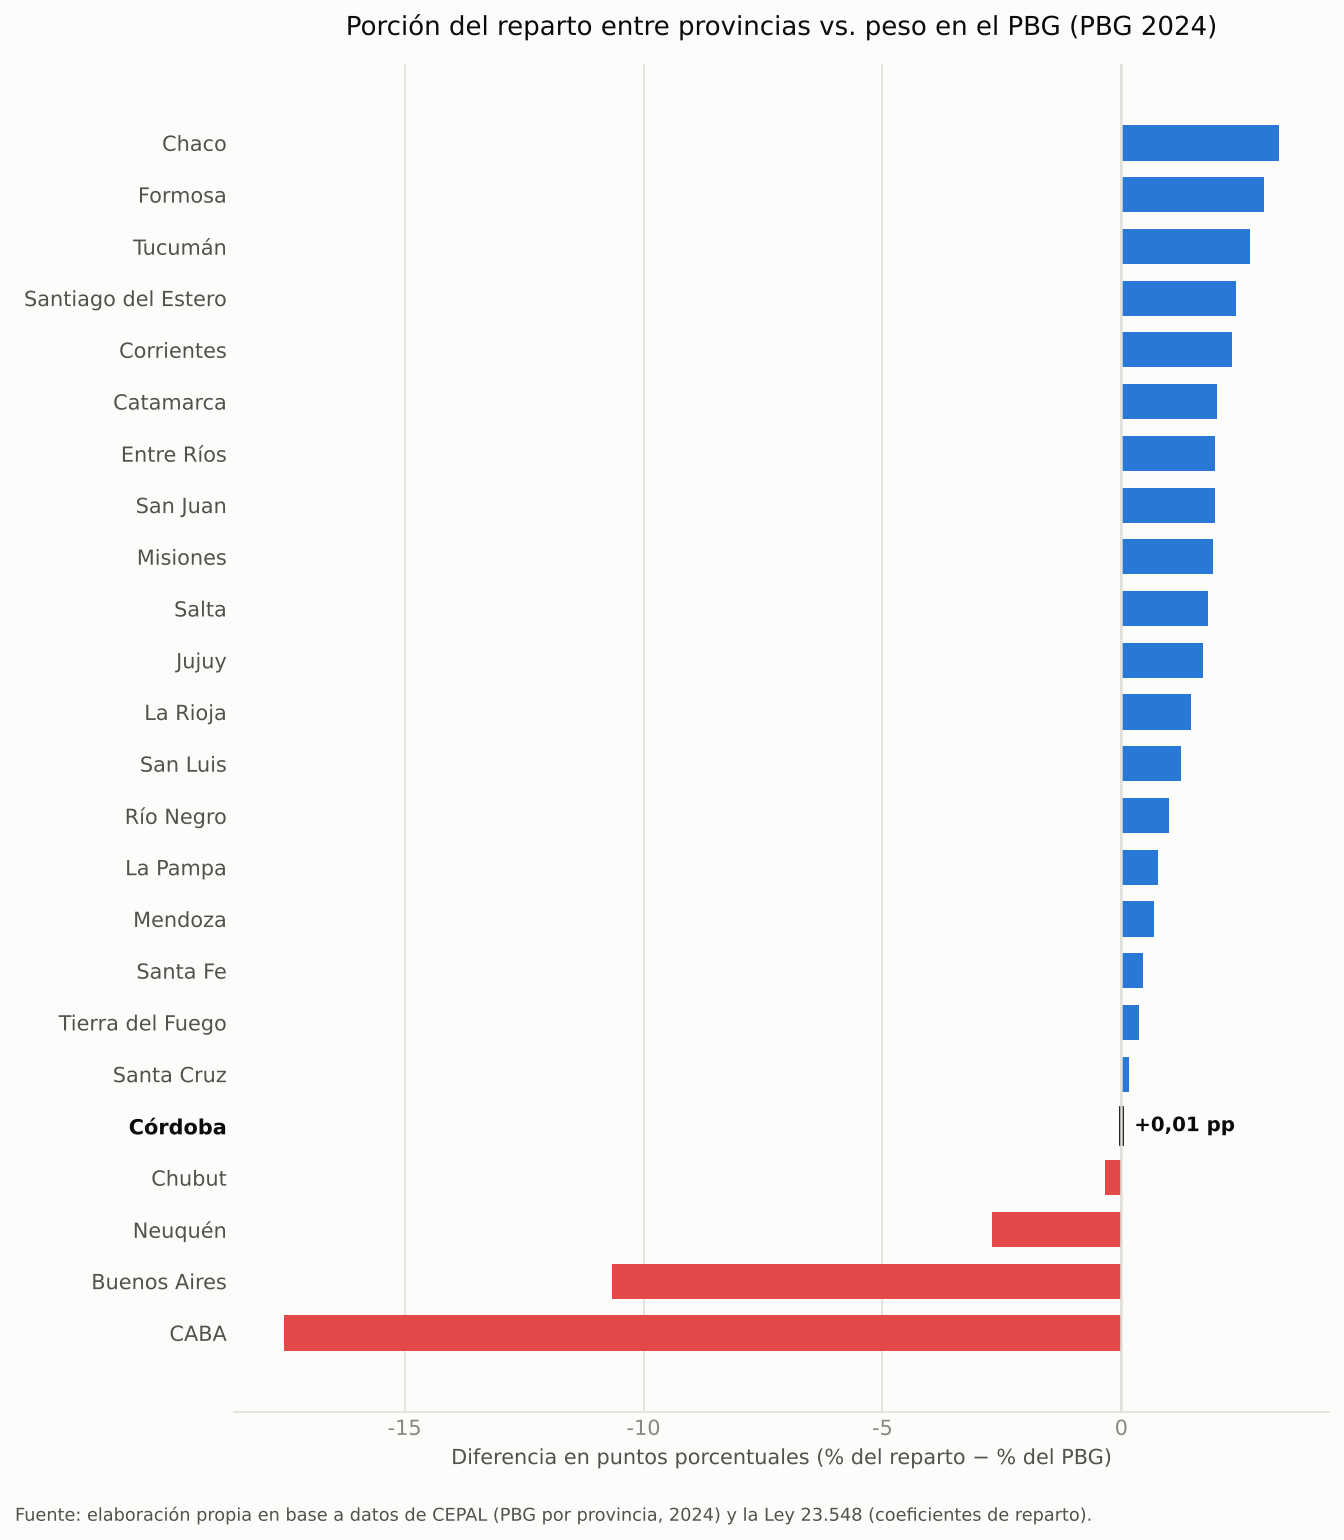

In [3]:
orden = df.sort_values("diferencia_pp", ascending=True).reset_index(drop=True)
colores = [COLOR_POSITIVO if v >= 0 else COLOR_NEGATIVO for v in orden["diferencia_pp"]]
bordes = [COLOR_CORDOBA_BORDE if p == "Córdoba" else "none" for p in orden["provincia"]]
grosor_borde = [1.8 if p == "Córdoba" else 0 for p in orden["provincia"]]

fig, ax = plt.subplots(figsize=(9, 10), dpi=150)
bars = ax.barh(
    orden["provincia"], orden["diferencia_pp"],
    color=colores, edgecolor=bordes, linewidth=grosor_borde, height=0.68,
)

ax.axvline(0, color=GRID_COLOR, linewidth=1.2)
ax.set_title(
    "Porción del reparto entre provincias vs. peso en el PBG (PBG 2024)",
    fontsize=12.5, color=INK_PRIMARY, pad=14,
)
ax.set_xlabel("Diferencia en puntos porcentuales (% del reparto − % del PBG)", fontsize=10)
ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: "0" if abs(x) < 1e-9 else f"{x:+.0f}"))

fila_cba = orden[orden["provincia"] == "Córdoba"].iloc[0]
ax.annotate(
    f"{fila_cba['diferencia_pp']:+.2f} pp".replace(".", ","),
    (max(fila_cba["diferencia_pp"], 0), orden.index[orden["provincia"] == "Córdoba"][0]),
    textcoords="offset points", xytext=(6, 0), va="center", fontsize=9.5,
    color=INK_PRIMARY, fontweight="bold",
)

# Resaltar la etiqueta de Córdoba en el eje y
for label in ax.get_yticklabels():
    if label.get_text() == "Córdoba":
        label.set_fontweight("bold")
        label.set_color(INK_PRIMARY)
    else:
        label.set_color(INK_SECONDARY)

fig.tight_layout()
guardar_con_fuente(fig, FIGURES_DIR / "aporte_vs_recibo_ranking.png", "CEPAL (PBG por provincia, 2024) y la Ley 23.548 (coeficientes de reparto)")
plt.show()

Córdoba recibe el 8,58% de lo que se reparte entre provincias y representa el 8,57% del
PBG nacional: una diferencia de +0,01 puntos porcentuales, prácticamente nula. Con este
proxy, Córdoba recibe casi exactamente en proporción a su peso económico, y lo mismo
pasa, con diferencias chicas, con Santa Fe (+0,5 pp) y Mendoza (+0,7 pp).

Las que quedan claramente por debajo son CABA (−17,5 pp), Buenos Aires (−10,7 pp) y
Neuquén (−2,7 pp). Del otro lado, las que más reciben en relación a su PBG son Chaco
(+3,3 pp), Formosa (+3,0 pp) y Tucumán (+2,7 pp). Es coherente con el objetivo original
del régimen de 1988 de redistribuir hacia las provincias de menor desarrollo relativo, y
con un problema conocido: el coeficiente de Buenos Aires quedó bajo respecto de su peso
económico y poblacional.

Esto dice que Córdoba es neutral **dentro de la coparticipación**, no en su relación
fiscal con la Nación (secciones 3 y 4).

Si a CABA se le computa el 2,95% que efectivamente cobra con la cautelar, su porción del
reparto sube a 4,9% y su brecha se achica a −15,0 pp; la de Córdoba pasa a −0,2 pp. No
cambia la lectura.

### Con lo que cada jurisdicción efectivamente recibió en 2025

El ranking de arriba usa el coeficiente legal. El Núcleo 5 muestra que lo que cada
jurisdicción cobró en 2025 se aparta de ese coeficiente casi solo por la compensación
del Consenso Fiscal, que va en un 56% a Buenos Aires. Si en vez del coeficiente uso la
participación efectiva de 2025, la brecha de Buenos Aires baja de −10,7 a −9,2 puntos y
la de Córdoba pasa de +0,01 a −0,3; el resto se mueve menos de 0,15 puntos.

In [4]:
recibido_2025 = pd.read_csv(BASE_DIR / "data" / "processed" / "comparativo_provincias.csv")
efectiva = df.merge(recibido_2025[["provincia", "participacion_2025"]], on="provincia")
efectiva["diferencia_efectiva_pp"] = (efectiva["participacion_2025"] - efectiva["pct_pbg_aporte"]) * 100
efectiva["cambio_pp"] = efectiva["diferencia_efectiva_pp"] - efectiva["diferencia_pp"]
efectiva[["provincia", "diferencia_pp", "diferencia_efectiva_pp", "cambio_pp"]].sort_values(
    "cambio_pp", key=abs, ascending=False
).head(5).round(2)

,provincia,diferencia_pp,diferencia_efectiva_pp,cambio_pp
22,Buenos Aires,-10.66,-9.17,1.49
19,Córdoba,0.01,-0.28,-0.29
6,Entre Ríos,1.95,1.82,-0.13
16,Santa Fe,0.45,0.33,-0.12
9,Salta,1.82,1.93,0.12


## 3. Lo que esta comparación no mide

La brecha contra el PBG mira solo el reparto de la Ley 23.548. Una medida completa de lo
que cada provincia aporta y recibe (el "residuo fiscal") tendría que sumar, al menos:

- **Impuestos nacionales que no se coparticipan.** El principal son las retenciones a
  las exportaciones, que van enteras al Tesoro Nacional. Para Córdoba, una de las
  principales provincias agroexportadoras, es la parte más importante que falta, y la
  estimo en la sección siguiente.
- **Gasto nacional directo en cada provincia.** Por ejemplo, los subsidios a la energía
  y al transporte, que durante buena parte de 2003-2023 se concentraron en el AMBA. Del
  lado de lo que "recibe", Buenos Aires y CABA quedan subestimadas en este núcleo.
- **Transferencias no automáticas.** Las que Nación decide por fuera de la ley (obras,
  programas, Aportes del Tesoro Nacional), que no siguen ningún coeficiente.
- **Previsión social.** Córdoba no transfirió su caja de jubilaciones a la Nación, así
  que paga sus jubilaciones provinciales con recursos propios, y la financiación del
  déficit de esa caja por parte de la ANSES es un reclamo recurrente de la provincia.

Ninguna de estas partidas está en el repositorio con apertura por provincia, salvo la
estimación de retenciones de abajo. Por eso este núcleo responde una pregunta más
acotada que "cuánto aporta y cuánto recibe Córdoba".

## 4. Las retenciones que genera la producción de Córdoba

Estimo qué parte de las retenciones nacionales de cada año corresponde a Córdoba,
repartiendo el total según su participación en las exportaciones por origen provincial
(INDEC). Como las retenciones se concentran en el agro y la agroindustria, la estimación
principal usa la participación de Córdoba en las exportaciones de productos primarios y
manufacturas de origen agropecuario (15%-19% según el año). Como cota baja uso su
participación en el total de las exportaciones (10%-15%), que le asigna también una
parte de lo que se cobra sobre combustibles e industria, donde Córdoba pesa poco.

Es una estimación de orden de magnitud: no tengo las alícuotas por producto, y quien
soporta el impuesto (en buena medida el productor, vía un precio más bajo) no es
necesariamente quien lo paga. Detalle en `scripts/build_retenciones_cordoba.py` y en
`docs/methodology.md`.

**Cómo leer el gráfico.** Las dos series están en billones de pesos de 2025. La línea
azul es la coparticipación que recibe Córdoba. La naranja es la estimación principal de
las retenciones que se cobran sobre su producción, y la franja sombreada va hasta la
estimación más baja. Cuando la naranja se acerca a la azul, lo que Nación se lleva de la
producción cordobesa sin repartirlo es tan grande como lo que le devuelve por
coparticipación.

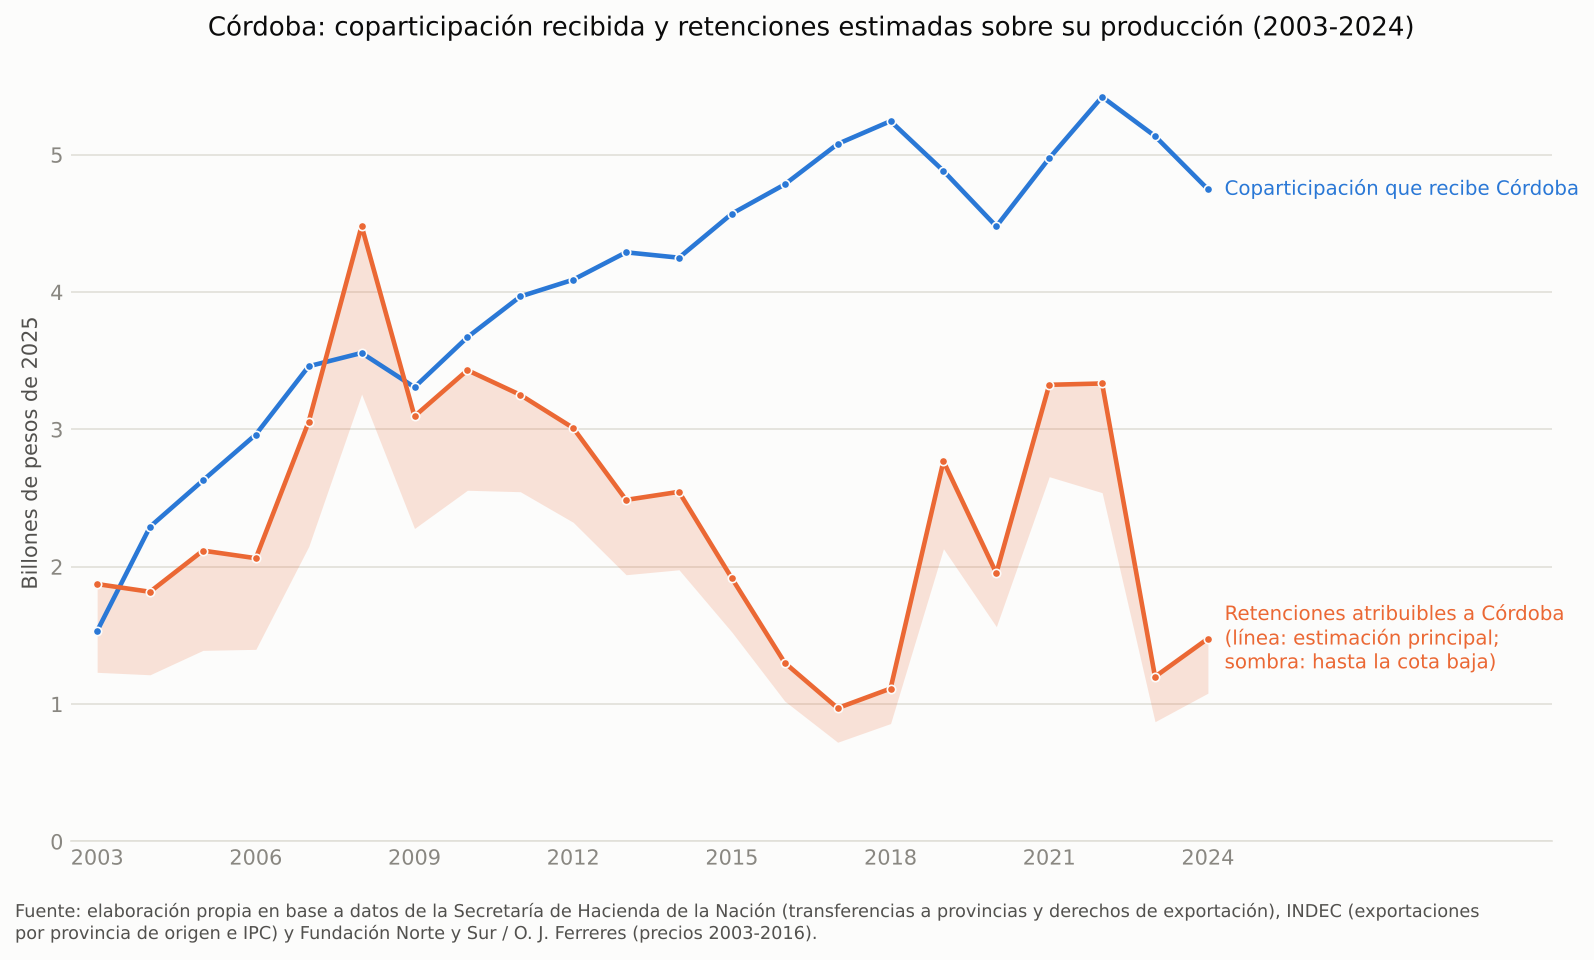

Retenciones acumuladas 2003-2024 / coparticipación acumulada: 59%


,participacion_cordoba_pp_moa,retenciones_sobre_coparticipacion,retenciones_sobre_coparticipacion_cota_baja
anio,,,
2003,0.17,1.22,0.80
2008,0.19,1.26,0.92
2015,0.19,0.42,0.33
2017,0.18,0.19,0.14
2021,0.19,0.67,0.53
2022,0.19,0.62,0.47
2023,0.17,0.23,0.17
2024,0.17,0.31,0.23


In [5]:
retenciones = pd.read_csv(BASE_DIR / "data" / "processed" / "retenciones_cordoba.csv").set_index("anio")
r = retenciones / 1e6  # billones de pesos de 2025

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
ax.plot(r.index, r["coparticipacion_cordoba_millones_pesos_2025"], color=COLOR_CORDOBA, linewidth=2.2,
        marker="o", markersize=4, markerfacecolor=COLOR_CORDOBA, markeredgecolor=SURFACE, markeredgewidth=0.8)
ax.fill_between(r.index, r["retenciones_cordoba_cota_baja_millones_pesos_2025"],
                r["retenciones_cordoba_millones_pesos_2025"], color=COLOR_RETENCIONES, alpha=0.18, linewidth=0)
ax.plot(r.index, r["retenciones_cordoba_millones_pesos_2025"], color=COLOR_RETENCIONES, linewidth=2.2,
        marker="o", markersize=4, markerfacecolor=COLOR_RETENCIONES, markeredgecolor=SURFACE, markeredgewidth=0.8)

ultimo = r.index.max()
ax.annotate("Coparticipación que recibe Córdoba", (ultimo, r.loc[ultimo, "coparticipacion_cordoba_millones_pesos_2025"]),
            xytext=(8, 0), textcoords="offset points", ha="left", va="center", fontsize=9.5, color=COLOR_CORDOBA)
ax.annotate("Retenciones atribuibles a Córdoba\n(línea: estimación principal;\nsombra: hasta la cota baja)",
            (ultimo, r.loc[ultimo, "retenciones_cordoba_millones_pesos_2025"]),
            xytext=(8, 0), textcoords="offset points", ha="left", va="center", fontsize=9.5, color=COLOR_RETENCIONES)

ax.set_title("Córdoba: coparticipación recibida y retenciones estimadas sobre su producción (2003-2024)",
             fontsize=12.5, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Billones de pesos de 2025", fontsize=10)
ax.set_xlim(2002.5, 2030.5)
ax.set_xticks(range(2003, 2025, 3))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
guardar_con_fuente(fig, FIGURES_DIR / "cordoba_retenciones_vs_coparticipacion.png", "la Secretaría de Hacienda de la Nación (transferencias a provincias y derechos de exportación), INDEC (exportaciones por provincia de origen e IPC) y " + FERRERES)
plt.show()

acumulado = (retenciones["retenciones_cordoba_millones_pesos_2025"].sum()
             / retenciones["coparticipacion_cordoba_millones_pesos_2025"].sum())
print(f"Retenciones acumuladas 2003-{ultimo} / coparticipación acumulada: {acumulado:.0%}")
retenciones[["participacion_cordoba_pp_moa", "retenciones_sobre_coparticipacion",
             "retenciones_sobre_coparticipacion_cota_baja"]].loc[[2003, 2008, 2015, 2017, 2021, 2022, 2023, 2024]].round(2)

Las retenciones atribuibles a la producción de Córdoba son del mismo orden de magnitud
que la coparticipación que recibe la provincia. En 2024 fueron unos \$1,48 billones (en
pesos de 2025; \$1,08 billones con la cota baja), el 31% de su coparticipación (23% con
la cota baja). Sumando 2003-2024, equivalen a alrededor del 59% de toda la
coparticipación que recibió Córdoba en esos años.

La línea naranja se mueve mucho más que la azul, porque depende de las alícuotas, de los
precios internacionales y de la cosecha. Sus quiebres coinciden con:

- **2003-2008, la suba:** las retenciones volvieron en 2002, después de la devaluación,
  y crecieron con los precios de los granos. En 2003 superaron a la coparticipación
  (122%), pero ahí pesa que la coparticipación estaba en el piso de la crisis.
- **2008, el máximo (126% de la coparticipación):** precios internacionales récord. Es
  el año del conflicto por la Resolución 125, que proponía retenciones móviles y quedó
  sin efecto.
- **2009-2015, la baja:** la sequía de 2009 y, después, precios de los granos más bajos.
- **2016-2018, el piso:** en diciembre de 2015 se eliminaron las retenciones a casi
  todos los productos, salvo la soja, que bajó de a poco.
- **2019, el salto:** en septiembre de 2018 se volvieron a cobrar retenciones a todas
  las exportaciones.
- **2021-2022 (62%-67% de la coparticipación):** precios altos.
- **2023, la caída:** la sequía más fuerte en décadas.

Esto cambia la lectura de la sección 2. Dentro de la coparticipación, Córdoba es
neutral; frente a la Nación, no: una parte sustancial de los impuestos que genera su
producción no vuelve por ningún régimen automático. No alcanza para calcular un residuo
fiscal (falta el gasto nacional en la provincia), pero muestra que mirar solo la Ley
23.548 deja afuera la discusión fiscal que más le importa a Córdoba.

## 5. Limitaciones de este análisis

Esto no es una medición directa de cuánto aporta cada provincia a la recaudación
tributaria nacional coparticipable — el PBG es un proxy, y tiene un problema de
atribución geográfica conocido y significativo.

Las grandes empresas suelen tributar donde tienen su sede fiscal, no donde generan la
actividad económica, y muchas con operaciones en todo el país tienen domicilio fiscal en
CABA. Por eso, en las estadísticas de recaudación por jurisdicción, buena parte de lo
que se genera en otras provincias (Córdoba incluida) figura como pagado en CABA. Si en
vez del PBG usara esa recaudación, CABA aparecería aportando todavía más y las
provincias productivas, menos. El PBG está más cerca de dónde se genera la actividad,
pero no mide directamente lo que tributa cada provincia.

El PBG (2024) se compara con el reparto **entre provincias** (coeficientes
renormalizados para sumar 100%), no con la masa coparticipable total. Eso hace las dos
columnas comparables, pero deja afuera una pregunta distinta: cuánto se queda Nación del
total, que no es lo que mide este núcleo.

El PBG de la fuente está a precios constantes de 2004: la participación de cada
provincia en 2024 está calculada con los precios relativos de 2004, no con los de 2024.
En provincias donde cambió mucho el precio de lo que producen respecto del resto (por
ejemplo, las petroleras), la participación a precios corrientes podría ser distinta. La
fuente no trae una serie a precios corrientes, así que no lo puedo cuantificar.

Además, el PBG que uso es de un solo año (2024, preliminar), mientras que el
coeficiente de coparticipación es esencialmente fijo desde 1988. Comparar una foto de
la estructura económica de un año puntual contra un coeficiente que no se mueve en el
tiempo no capta cómo cambió el peso relativo de cada provincia a lo largo de casi 40
años — que es, de hecho, el argumento central de por qué el esquema de 1988 está
desactualizado.

Un análisis más riguroso del aporte tributario real necesitaría datos de recaudación
por jurisdicción de origen económico (no de domicilio fiscal), que no encontré
disponibles de forma pública y desagregada por provincia.

La estimación de retenciones de la sección 4 reparte el total nacional según la
participación de Córdoba en las exportaciones de productos primarios y manufacturas de
origen agropecuario. Supone que todos los productos de esos rubros pagan la misma
alícuota, cuando en realidad la soja y sus derivados pagaron bastante más que el maíz o
el trigo. Si Córdoba exporta relativamente más soja que el promedio, la estimación queda
corta; si exporta relativamente más maíz o maní, queda larga. El origen provincial de
INDEC, además, no siempre coincide con el lugar exacto de producción.